# Punto 6 (0.8) — HSI: ecualización del histograma

Aplique la transformación a su imagen RGB.

- Paso 1. Convierta su imagen RGB al espacio HSI
- Paso 2. Aplique correctamente la ecualización del histograma a su imagen en HSI, obtenida en el Paso 1
- Paso 3. Convierta la imagen obtenida en el Paso 2 al espacio RGB

"Correctamente" significa ecualizar solo el componente de Intensidad: Tono y Saturación definen el color, y ecualizarlos lo alteraría.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import sys
sys.path.append("..")
from colorspaces import rgb_to_hsi, hsi_to_rgb


## Imagen original RGB

(1024, 1024, 3) uint8


(np.float64(-0.5), np.float64(1023.5), np.float64(1023.5), np.float64(-0.5))

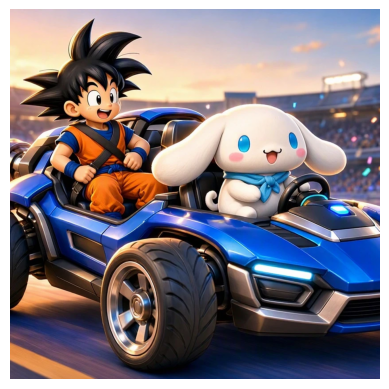

In [2]:
img = np.array(Image.open("../images/mi_imagen.png").convert("RGB"))
print(img.shape, img.dtype)

plt.figure()
plt.imshow(img)
plt.axis("off")


## Paso 1 — RGB a HSI

In [3]:
hsi = rgb_to_hsi(img)


## Paso 2 — Ecualización del histograma en HSI

In [4]:
intensidad = np.round(hsi[..., 2] * 255).astype(np.uint8)
intensidad_eq = cv2.equalizeHist(intensidad)


## Paso 3 — Vuelta a RGB

In [5]:
hsi_eq = hsi.copy()
hsi_eq[..., 2] = intensidad_eq / 255.0
resultado = hsi_to_rgb(hsi_eq)

Image.fromarray(resultado).save("../results/punto6_transformada.png")


## Comparación original vs transformada

Complete la tabla con la imagen original RGB y la imagen transformada.

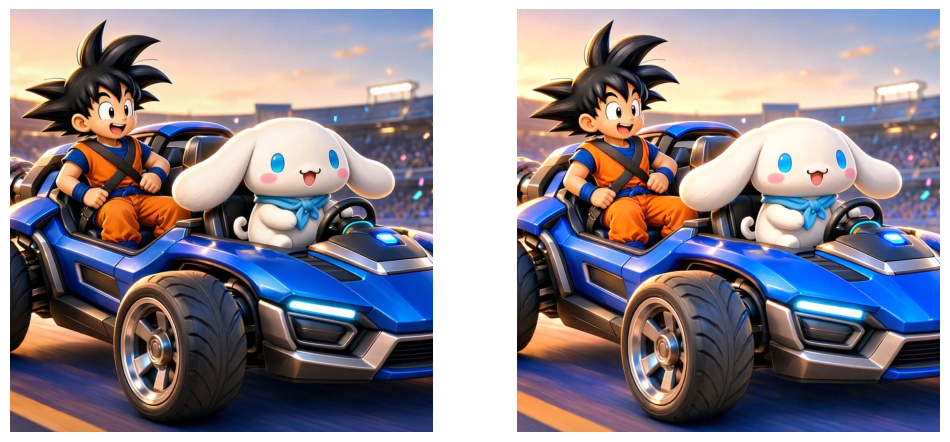

In [6]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(resultado)
plt.axis("off")
plt.savefig("../results/punto6_comparacion.png", bbox_inches="tight", pad_inches=0)
